```markdown
# Team 
- Daram Vishnuvardhan | CS24MTECH12002
- madhan V | CS24MTECH11021
- P rushikeshvar reddy| CS24MTECH11018

```

In [4]:
%pip install numpy==1.26.4 --force-reinstall --no-cache-dir


%pip install pandas networkx matplotlib scikit-learn gensim openpyxl tqdm --quiet

ERROR: Ignored the following versions that require a different python version: 1.25.0 Requires-Python >=3.9; 1.25.1 Requires-Python >=3.9; 1.25.2 Requires-Python >=3.9; 1.26.0 Requires-Python <3.13,>=3.9; 1.26.1 Requires-Python <3.13,>=3.9; 1.26.2 Requires-Python >=3.9; 1.26.3 Requires-Python >=3.9; 1.26.4 Requires-Python >=3.9; 2.0.0 Requires-Python >=3.9; 2.0.1 Requires-Python >=3.9; 2.0.2 Requires-Python >=3.9; 2.1.0 Requires-Python >=3.10; 2.1.0rc1 Requires-Python >=3.10; 2.1.1 Requires-Python >=3.10; 2.1.2 Requires-Python >=3.10; 2.1.3 Requires-Python >=3.10; 2.2.0 Requires-Python >=3.10; 2.2.0rc1 Requires-Python >=3.10; 2.2.1 Requires-Python >=3.10; 2.2.2 Requires-Python >=3.10; 2.2.3 Requires-Python >=3.10; 2.2.4 Requires-Python >=3.10; 2.2.5 Requires-Python >=3.10
ERROR: Could not find a version that satisfies the requirement numpy==1.26.4 (from versions: 1.3.0, 1.4.1, 1.5.0, 1.5.1, 1.6.0, 1.6.1, 1.6.2, 1.7.0, 1.7.1, 1.7.2, 1.8.0, 1.8.1, 1.8.2, 1.9.0, 1.9.1, 1.9.2, 1.9.3, 1.10.

In [5]:
import pandas as pd
import networkx as nx
import numpy as np
import random
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import torch.nn as nn
import torch.optim as optim
from collections import defaultdict

In [6]:
# Load the data
df = pd.read_excel("Payments.xlsx")
df.columns = ['source', 'target', 'amount']

torch.cuda.is_available()

In [7]:
torch.cuda.is_available()

False

```markdown
# Node2VecTorch: Functional Description

## Overview
`Node2VecTorch` learns dense vector embeddings for nodes in a graph by simulating random walks and applying a skip-gram model with negative sampling.  
The embeddings capture both local and global graph structure, useful for tasks like node classification, clustering, and link prediction.



## Methods

### `generate_walks()`
Simulates multiple random walks starting from each node to create sequences of node visits, reflecting the graph's topology.

### `random_walk(start)`
Performs a single random walk by randomly selecting outgoing neighbors at each step, terminating early if no neighbors exist.

### `generate_skipgram_pairs(walks)`
Processes node walks into center-context pairs based on a randomly sampled window size, forming training samples for the skip-gram model.

### `train(pairs, epochs=5, lr=0.01)`
Optimizes node embeddings by maximizing similarity for positive (center, context) pairs and minimizing similarity for randomly sampled negative pairs using BCE loss and Adam optimizer.  
Returns L2-normalized node embeddings.

---

## Core Details
- Random walks model both local neighborhoods and broader graph structures.
- Negative sampling allows scalable training without computing full softmax over all nodes.
- Final embeddings are normalized to stabilize performance in downstream tasks.
- Automatically uses GPU if available.

---

## Process Summary
```
plaintext
Graph → Random Walks → Center-Context Pairs → Train with Negative Sampling → Normalized Embeddings

```

```



In [8]:
class Node2Vec:
    def __init__(self, graph, dimensions=64, walk_length=10, num_walks=100, window_size=5, num_negative=5, batch_size=1024):
        self.graph = graph
        self.walk_length = walk_length
        self.num_walks = num_walks
        self.window_size = window_size
        self.dimensions = dimensions
        self.num_negative = num_negative
        self.batch_size = batch_size

        self.nodes = list(graph.nodes())
        self.node2idx = {node: i for i, node in enumerate(self.nodes)}
        self.idx2node = {i: node for node, i in self.node2idx.items()}

    def generate_walks(self):
        walks = []
        for _ in range(self.num_walks):
            random.shuffle(self.nodes)
            for node in self.nodes:
                walk = self.random_walk(node)
                walks.append(walk)
        return walks

    def random_walk(self, start):
        walk = [start]
        while len(walk) < self.walk_length:
            cur = walk[-1]
            neighbors = list(self.graph.successors(cur))
            if not neighbors:
                break
            walk.append(random.choice(neighbors))
        return walk

    def generate_skipgram_pairs(self, walks):
        pairs = []
        for walk in walks:
            for i, center in enumerate(walk):
                actual_window = random.randint(1, self.window_size)
                window = walk[max(i - actual_window, 0): i + actual_window + 1]
                for context in window:
                    if context != center:
                        pairs.append((self.node2idx[center], self.node2idx[context]))
        return pairs

    def train(self, pairs, epochs=5, lr=0.01):
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        num_nodes = len(self.nodes)
        embed_in = nn.Embedding(num_nodes, self.dimensions).to(device)
        embed_out = nn.Embedding(num_nodes, self.dimensions).to(device)

        optimizer = optim.Adam(list(embed_in.parameters()) + list(embed_out.parameters()), lr=lr)
        loss_fn = nn.BCEWithLogitsLoss(reduction='mean')

        pairs = np.array(pairs)

        for epoch in range(epochs):
            np.random.shuffle(pairs)
            total_loss = 0
            total_samples = 0

            for i in tqdm(range(0, len(pairs), self.batch_size), desc=f"Epoch {epoch+1}"):
                batch = pairs[i:i+self.batch_size]
                center_batch = torch.tensor(batch[:, 0], dtype=torch.long, device=device)
                context_batch = torch.tensor(batch[:, 1], dtype=torch.long, device=device)

                center_embeds = embed_in(center_batch)
                context_embeds = embed_out(context_batch)

                pos_scores = torch.sum(center_embeds * context_embeds, dim=1)
                pos_labels = torch.ones(pos_scores.size(), device=device)
                loss = loss_fn(pos_scores, pos_labels)

                # Negative sampling using uniform distribution
                negative_samples = torch.randint(0, num_nodes, (self.num_negative * center_batch.size(0),), device=device)
                neg_contexts = embed_out(negative_samples)
                repeated_centers = center_embeds.repeat_interleave(self.num_negative, dim=0)

                neg_scores = torch.sum(repeated_centers * neg_contexts, dim=1)
                neg_labels = torch.zeros(neg_scores.size(), device=device)
                loss += loss_fn(neg_scores, neg_labels)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                total_loss += loss.item() * center_batch.size(0)
                total_samples += center_batch.size(0)

            avg_loss = total_loss / total_samples
            print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

        # Normalize embeddings
        final_embeds = embed_in.weight.detach().cpu()
        norms = torch.norm(final_embeds, dim=1, keepdim=True)
        return (final_embeds / norms).numpy()


In [9]:

# Step 1: Create a MultiDiGraph
multi_graph = nx.MultiDiGraph()
for _, row in df.iterrows():
    multi_graph.add_edge(row['source'], row['target'], weight=row['amount'])

In [10]:

# Step 2: Convert to a simple DiGraph with aggregated edge weights
graph = nx.DiGraph()
for u, v, data in multi_graph.edges(data=True):
    if graph.has_edge(u, v):
        graph[u][v]['weight'] += data['weight']
    else:
        graph.add_edge(u, v, weight=data['weight'])

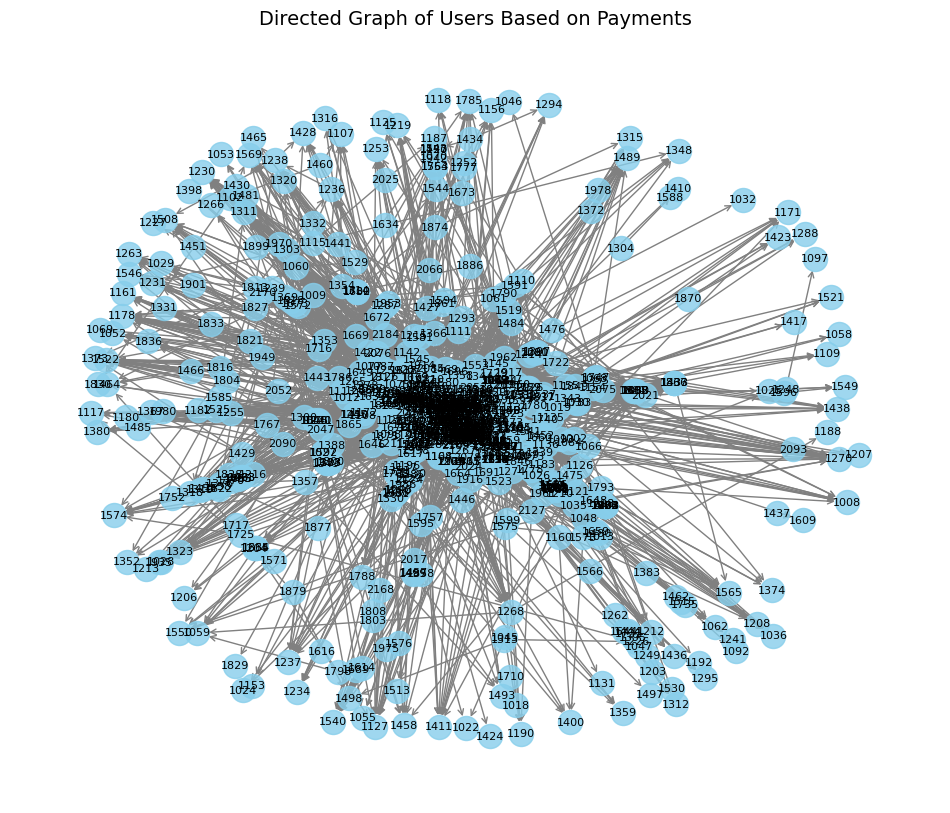

In [11]:

# Step 3: Visualize the directed graph
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(graph, seed=42)
weights = [graph[u][v]['weight'] for u, v in graph.edges()]
nx.draw_networkx_nodes(graph, pos, node_size=300, node_color='skyblue', alpha=0.8)
nx.draw_networkx_edges(graph, pos, edgelist=graph.edges(), arrowstyle='->', arrowsize=10,
                       edge_color='gray', width=1)
nx.draw_networkx_labels(graph, pos, font_size=8)
plt.title("Directed Graph of Users Based on Payments", fontsize=14)
plt.axis('off')
plt.show()

In [12]:
from tqdm import tqdm
# Step 5: Train node2vec and get embeddings

n2v = Node2Vec(graph)
walks = n2v.generate_walks()
pairs = n2v.generate_skipgram_pairs(walks)
embeddings = n2v.train(pairs, epochs=20)

Epoch 1: 100%|██████████| 1868/1868 [00:05<00:00, 359.61it/s]


Epoch 1, Loss: 0.9711


Epoch 2: 100%|██████████| 1868/1868 [00:05<00:00, 361.47it/s]


Epoch 2, Loss: 0.5538


Epoch 3: 100%|██████████| 1868/1868 [00:05<00:00, 364.59it/s]


...

Epoch 18, Loss: 0.5280


Epoch 19: 100%|██████████| 1868/1868 [00:04<00:00, 380.22it/s]


Epoch 19, Loss: 0.5280


Epoch 20: 100%|██████████| 1868/1868 [00:05<00:00, 345.28it/s]

Epoch 20, Loss: 0.5276


/home/vishnu/miniconda3/envs/fraud_analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


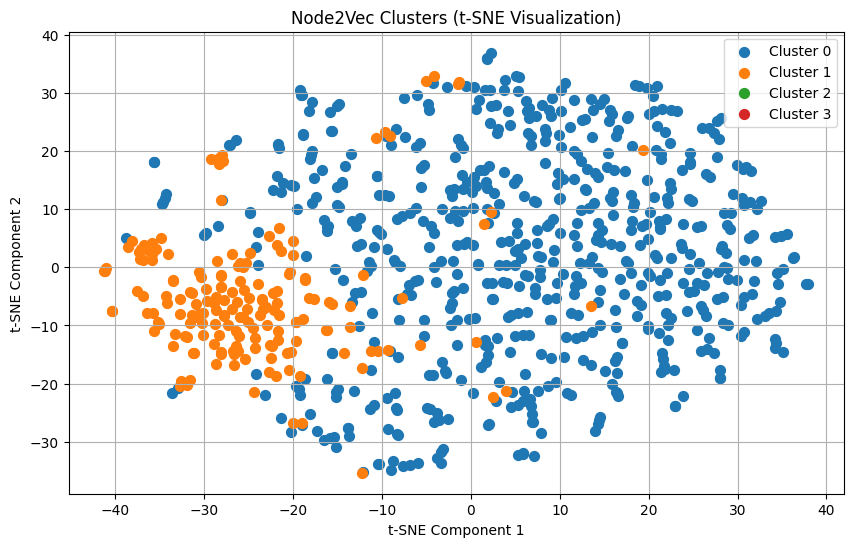

In [13]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Step 6: Apply clustering
kmeans = KMeans(n_clusters=2, random_state=42)
clusters = kmeans.fit_predict(embeddings)

# Step 7: Reduce dimensions using t-SNE
tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, random_state=42)
reduced_embeddings = tsne.fit_transform(embeddings)

# Step 8: Visualize clusters using t-SNE with legends
plt.figure(figsize=(10, 6))
for cluster_id in range(4):
    plt.scatter(
        reduced_embeddings[clusters == cluster_id, 0],
        reduced_embeddings[clusters == cluster_id, 1],
        label=f'Cluster {cluster_id}',
        s=50
    )

plt.title("Node2Vec Clusters (t-SNE Visualization)")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend()
plt.grid(True)
plt.show()


/home/vishnu/miniconda3/envs/fraud_analytics/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


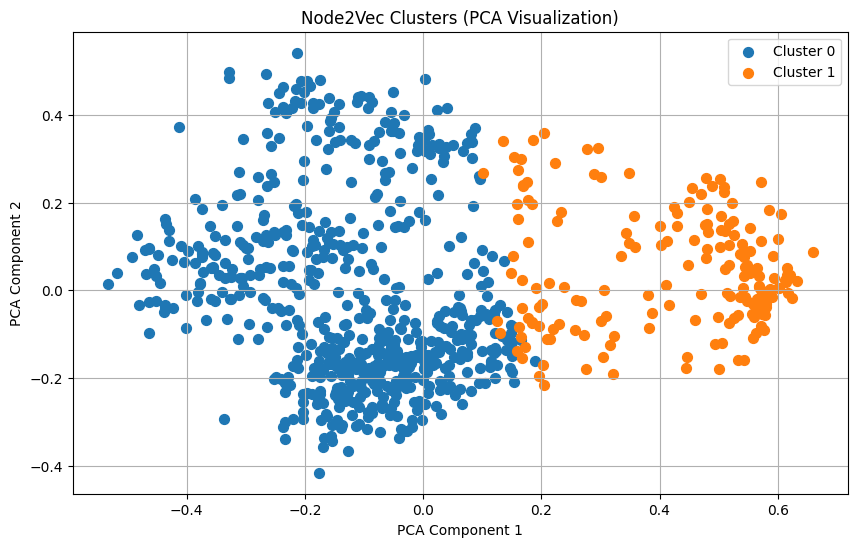

In [14]:
# Apply clustering
kmeans = KMeans(n_clusters=2, random_state=42)
clusters = kmeans.fit_predict(embeddings)

# Reduce dimensions for visualization
pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(embeddings)

# Visualize clusters using PCA with legends
plt.figure(figsize=(10, 6))
for cluster_id in range(2):
    plt.scatter(
        reduced_embeddings[clusters == cluster_id, 0],
        reduced_embeddings[clusters == cluster_id, 1],
        label=f'Cluster {cluster_id}',
        s=50
    )

plt.title("Node2Vec Clusters (PCA Visualization)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.grid(True)
plt.show()